# Evaluación de los encodings

Mide qué tan bien se distinguen las personas dentro de un `.pickle` de encodings.

A cada rostro se le busca el **vecino más cercano entre todos los demás** (nunca contra sí mismo) y la etiqueta de ese vecino es la predicción. Las distancias se calculan con `face_recognition.face_distance`, la misma función que usa `recognize_faces_image.py`.

Los gráficos usan los mismos colores que `evaluar.py` y no se guardan en disco: para copiarlos, clic derecho sobre la imagen.

## 1. Librerías

In [26]:
import pickle

import face_recognition
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import classification_report, confusion_matrix

### Colores

Los mismos de `evaluar.py`.

In [36]:
TEXTO = "#0b0b0b"         # texto principal
TEXTO_2 = "#52514e"       # ejes y etiquetas
GRILLA = "#e4e3df"        # lineas de grilla y bordes
FONDO_ENCABEZADO = "#f0efec"
FONDO_RESUMEN = "#f7f7f5"
AZULES = ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95"]  # claro -> oscuro
COLOR_SERIE = {"precision": "#2a78d6", "recall": "#eb6834", "f1-score": "#1baf7a"}

plt.rcParams.update({
    "text.color": TEXTO,
    "axes.labelcolor": TEXTO_2,
    "xtick.color": TEXTO_2,
    "ytick.color": TEXTO_2,
    "axes.edgecolor": GRILLA,
})

## 2. Cargar los encodings

Cambia `RUTA` para evaluar otro pickle (por ejemplo `runs/05_cnn.pickle`).

In [37]:
RUTA = "encodings.pickle"

with open(RUTA, "rb") as f:
    data = pickle.load(f)

X = np.array(data["encodings"])
y = np.array(data["names"])
etiquetas = sorted(set(y))

print(f"{RUTA}: {len(y)} rostros, {len(etiquetas)} personas")

encodings.pickle: 270 rostros, 8 personas


## 3. Predicción por vecino más cercano

La diagonal de `D` es la distancia de cada rostro a sí mismo (cero). Se pone en infinito para que nadie se reconozca a sí mismo, lo que daría un 1.000 falso.

In [38]:
D = np.array([face_recognition.face_distance(X, encoding) for encoding in X])
np.fill_diagonal(D, np.inf)

y_pred = y[D.argmin(axis=1)]
print(f"accuracy: {(y == y_pred).mean():.3f}")

accuracy: 0.978


## 4. Precision / recall / F1

In [39]:
print(classification_report(y, y_pred, zero_division=0, digits=3))

                precision    recall  f1-score   support

  Karla_Abarca      1.000     1.000     1.000        40
   Marco_Guapi      0.980     0.980     0.980        51
    alan_grant      1.000     0.917     0.957        12
claire_dearing      0.938     0.978     0.957        46
 ellie_sattler      0.967     1.000     0.983        29
   ian_malcolm      1.000     0.974     0.987        39
  john_hammond      0.944     0.944     0.944        18
    owen_grady      1.000     0.971     0.986        35

      accuracy                          0.978       270
     macro avg      0.979     0.971     0.974       270
  weighted avg      0.978     0.978     0.978       270



Las mismas métricas como DataFrame (se usan en los gráficos de abajo):

In [40]:
metricas = pd.DataFrame(
    classification_report(y, y_pred, zero_division=0, output_dict=True)
).T
metricas.loc["accuracy", ["precision", "recall"]] = np.nan
metricas.loc["accuracy", "support"] = len(y)
metricas["support"] = metricas["support"].astype(int)
metricas.round(3)

,precision,recall,f1-score,support
Karla_Abarca,1.000,1.000,1.000,40
Marco_Guapi,0.980,0.980,0.980,51
alan_grant,1.000,0.917,0.957,12
claire_dearing,0.938,0.978,0.957,46
ellie_sattler,0.967,1.000,0.983,29
ian_malcolm,1.000,0.974,0.987,39
john_hammond,0.944,0.944,0.944,18
owen_grady,1.000,0.971,0.986,35
accuracy,NaN,NaN,0.978,270
macro avg,0.979,0.971,0.974,270


## 5. Matriz de confusión

Filas = persona real, columnas = predicha. Lo que queda fuera de la diagonal son los errores.

In [41]:
cm = confusion_matrix(y, y_pred, labels=etiquetas)


## 6. Gráfico: matriz de confusión

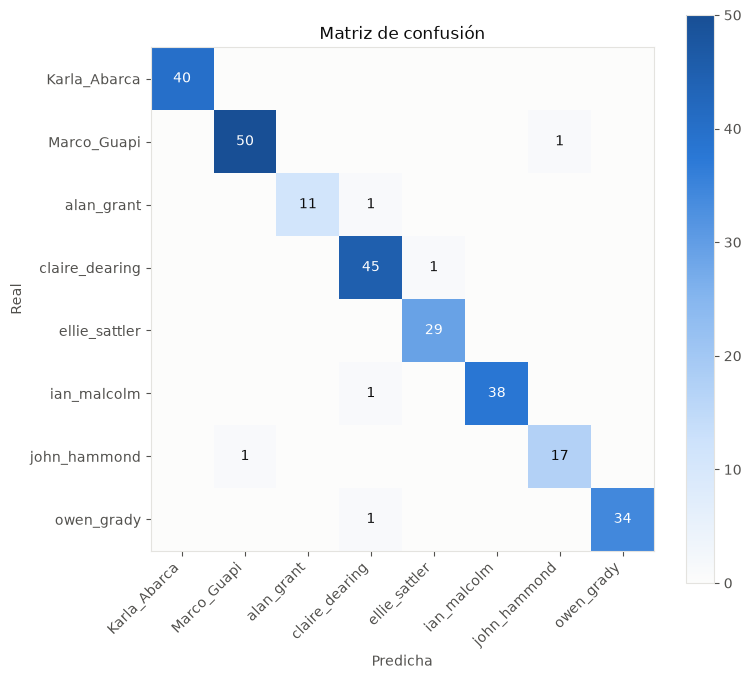

In [42]:
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap=LinearSegmentedColormap.from_list("azules", AZULES), vmin=0)
fig.colorbar(im, ax=ax)

ax.set_xticks(range(len(etiquetas)), etiquetas, rotation=45, ha="right")
ax.set_yticks(range(len(etiquetas)), etiquetas)
ax.set_xlabel("Predicha")
ax.set_ylabel("Real")
ax.set_title("Matriz de confusión")

# numero en cada celda: blanco sobre azul oscuro, negro sobre claro
umbral = cm.max() * 0.55
for i in range(len(etiquetas)):
    for j in range(len(etiquetas)):
        if cm[i, j]:
            color = "white" if cm[i, j] > umbral else TEXTO
            ax.text(j, i, cm[i, j], ha="center", va="center", color=color)

plt.tight_layout()
plt.show()

## 7. Gráfico: precision / recall / F1 por persona

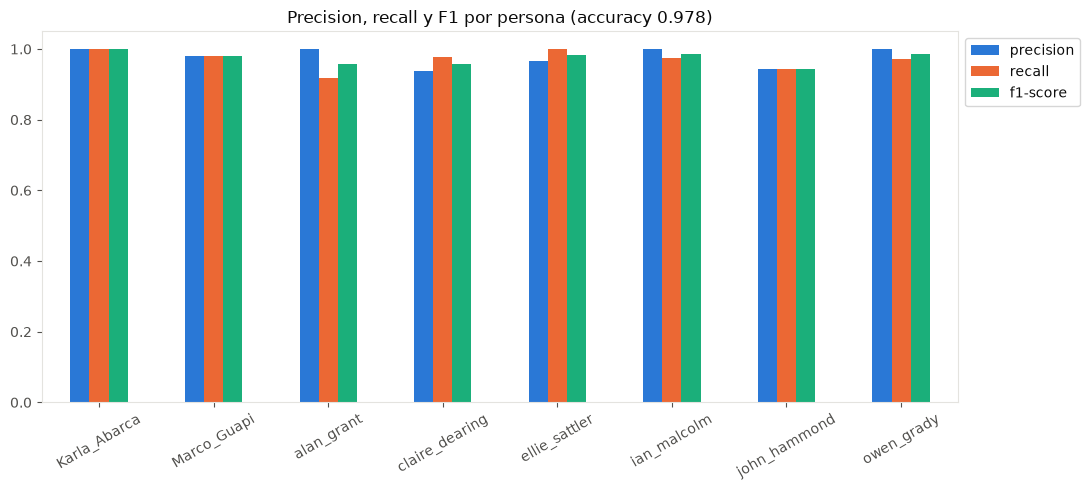

In [43]:
ax = metricas.loc[etiquetas, list(COLOR_SERIE)].plot.bar(
    figsize=(11, 5), rot=30, ylim=(0, 1.05),
    color=list(COLOR_SERIE.values()),
    title=f"Precision, recall y F1 por persona (accuracy {(y == y_pred).mean():.3f})",
)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## 8. Gráfico: tabla de métricas

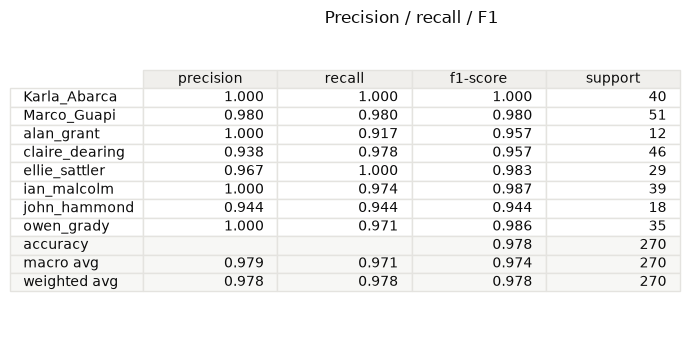

In [44]:
columnas = ["precision", "recall", "f1-score", "support"]
celdas = [
    ["" if pd.isna(v) else (f"{int(v)}" if c == "support" else f"{v:.3f}")
     for c, v in fila.items()]
    for _, fila in metricas[columnas].iterrows()
]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.axis("off")
ax.set_title("Precision / recall / F1")
tabla = ax.table(cellText=celdas, rowLabels=list(metricas.index), colLabels=columnas,
                 loc="center")

# colores: fila 0 = encabezado; despues de las personas = accuracy y promedios
for (fila, _), celda in tabla.get_celld().items():
    celda.set_edgecolor(GRILLA)
    if fila == 0:
        celda.set_facecolor(FONDO_ENCABEZADO)
    elif fila > len(etiquetas):
        celda.set_facecolor(FONDO_RESUMEN)

plt.tight_layout()
plt.show()